# 综合案例：PWM→XYZ 校正

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'lsq').is_dir():
    if root == root.parent:
        raise RuntimeError('Run inside the repository')
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from lsq import (finite_difference, whiten, gauss_newton,
                 levenberg_marquardt, dogleg, recursive_update)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (6.4, 3.3), 'font.size': 10,
                     'axes.grid': True, 'savefig.dpi': 130})

已知目标三刺激值，希望调整三通道PWM让实测XYZ逼近目标。这是一个三输入、三输出、可能含量化和测量噪声的逆问题。本章展示可复现实验框架，不将合成曲线当作真实屏幕的测量结论。

## 明确仿真假设

PWM取12位整数0—4095。低于96视为关闭；96以上的各通道响应连续、分段线性且单调。一个固定的正混色矩阵把通道发光量映射成归一化XYZ。单次测量加入标准差$2\times10^{-4}$的独立高斯噪声。真实设备的通道耦合、热漂移或非单调性需要重新测量，不能直接照搬此模型。

目标函数仍可写为$\tfrac12\|M(p)-X_{\rm target}\|^2$。若XYZ各分量噪声不同，应白化；本例三者采用同一噪声尺度。

target XYZ: [0.12418 0.14976 0.1032 ] initial error: 0.06697135746402544


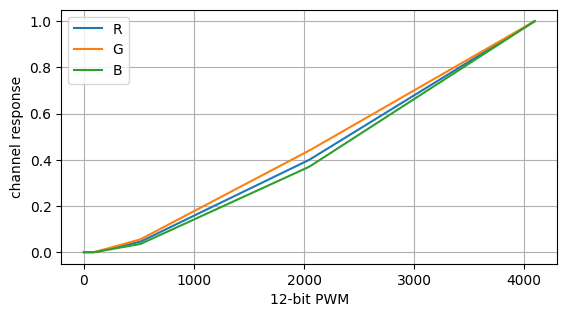

In [2]:
mix=np.array([[.52,.29,.18],[.23,.70,.07],[.03,.12,.94]])
knots=np.array([0,96,512,2048,4095.])
levels=np.array([[0,0,.045,.40,1.],
                 [0,0,.055,.44,1.],
                 [0,0,.035,.37,1.]])
def simulator(p):
    p=np.clip(np.rint(p),0,4095)
    light=np.array([np.interp(p[i],knots,levels[i]) for i in range(3)])
    return mix@light
rng=np.random.default_rng(115)
def measure(p,repeats=8):
    return simulator(p)+rng.normal(0,2e-4,(repeats,3)).mean(axis=0)
def measured_jacobian(p,delta=64):
    J=np.zeros((3,3))
    for k in range(3):
        plus=p.copy();minus=p.copy()
        plus[k]=min(4095,p[k]+delta)
        minus[k]=max(96,p[k]-delta)
        span=plus[k]-minus[k]
        J[:,k]=(measure(plus)-measure(minus))/span
    return J
target=simulator([820,960,740])
start=np.array([1100.,900.,1000.])
print('target XYZ:',target,'initial error:',np.linalg.norm(simulator(start)-target))
grid=np.linspace(0,4095,200)
for k in range(3):
    plt.plot(grid,np.interp(grid,knots,levels[k]),label='RGB'[k])
plt.xlabel('12-bit PWM');plt.ylabel('channel response');plt.legend();plt.show()

## 用实际扰动跨度估计双侧雅可比

每次只扰动一个通道，另外两通道固定。边界附近的实际差分跨度可能小于$2\delta$，分母必须使用实际跨度。扰动需要大于量化与噪声造成的不可分辨区，又不能大到跨越太多不同斜率段。重复测量只能在噪声足够独立时降低均值方差；系统漂移不会自动平均掉。

下面把PWM参数归一化为$u=p/4095$，避免导数尺度过小。先用阻尼局部最小二乘求步，再限制单次PWM改变量，量化后测量真实下降；失败则增大阻尼。始终保留误差最小的已测点。

PWM: [821. 959. 739.] status: target_reached noise-free error: 0.00026654803100767464
unreachable target: unreachable_upper_or_lower_bound


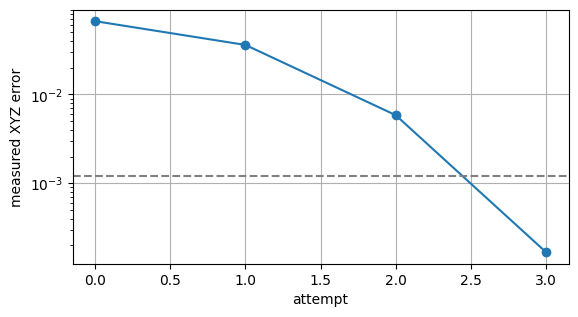

In [3]:
def calibrate(target,start,max_iter=45,tolerance=1.2e-3):
    p=np.clip(np.rint(start),96,4095).astype(float)
    upper=simulator([4095]*3)
    if np.any(target>upper+tolerance) or np.any(target<0):
        return p,'unreachable_upper_or_lower_bound',[]
    current=measure(p);error=np.linalg.norm(current-target)
    best=p.copy();best_error=error
    mu=1e-4;history=[error];rejects=0
    for _ in range(max_iter):
        if error <= tolerance:
            return p,'target_reached',history
        J=measured_jacobian(p)*4095
        residual=current-target
        du=np.linalg.lstsq(np.vstack([J,np.sqrt(mu)*np.eye(3)]),
                          np.r_[-residual,np.zeros(3)],rcond=None)[0]
        step=4095*du
        step*=min(1.,128/max(np.max(np.abs(step)),1e-12))
        candidate=np.clip(np.rint(p+step),96,4095)
        if np.array_equal(candidate,p):
            return best,'quantized_stall',history
        value=measure(candidate);candidate_error=np.linalg.norm(value-target)
        if candidate_error < error:
            p,current,error=candidate,value,candidate_error
            rejects=0;mu=max(mu/3,1e-9)
            if error<best_error:
                best,best_error=p.copy(),error
        else:
            rejects+=1;mu*=4
        history.append(error)
        if rejects>=8:
            return best,'no_measured_progress',history
    return best,'budget_exhausted',history
p,status,history=calibrate(target,start)
print('PWM:',p,'status:',status,'noise-free error:',np.linalg.norm(simulator(p)-target))
assert np.all((p>=96)&(p<=4095))
assert np.linalg.norm(simulator(p)-target)<.003
plt.semilogy(history,'o-');plt.axhline(1.2e-3,color='gray',linestyle='--')
plt.xlabel('attempt');plt.ylabel('measured XYZ error');plt.show()
_,unreachable,_=calibrate(np.array([2.,2.,2.]),start)
print('unreachable target:',unreachable)
assert unreachable != 'target_reached'

## 低灰平台和不可达目标

若扰动后量化值完全没变，数值雅可比可能为零。这时梯度小并不说明XYZ已经达到目标，应增大有效扰动、跨平台探测或报告无法分辨。本例从96以上开始，边界采用实际可用跨度；它并没有解决所有真实低灰平台问题。

逐分量上下界检查只能排除一部分不可达目标。即使目标的X、Y、Z分别都不超限，三者组合仍可能在设备色域外。应在预算、边界和重复测量下报告剩余误差，而不是永远迭代或伪称成功。

本例以一次平均测量的误差选择最好点，会有噪声选择偏差。真实验收应对最终点重新独立多次测量，按XYZ或色度/亮度各自容差确认；也要记录热稳定时间、测量顺序和环境条件。

## 练习与解答

练习：为什么不直接对XYZ误差逐分量分别调R、G、B？解答：混色矩阵使每个通道同时影响多个XYZ分量，需要考虑耦合。

练习：把差分扰动从64改为1，会怎样？解答：有效信号变小，导数中的测量噪声被放大，量化平台也更明显；具体效果可通过重复运行观察。

练习：如果增加B时实测Y下降，本模型是否足以解释？解答：不能；本模型混色系数和通道斜率均非负。真实现象需要排查耦合、测量时序、限流、热状态和图样条件，先验证模型再选择求解器。